# 2. Inferential Statistics

### Making Conclusions Beyond the Data!

## Why Inferential Statistics?

- We cannot survey the whole population!
- We rely on a **sample** to infer about the **population**.
- **Example:** Estimating election results from a small survey.

# Population vs Sample

| Term | Meaning | Example |
|---|---|---|
| **Population** | Entire group | All Flipkart users |
| **Sample** | Subset selected | 500 Flipkart users surveyed |

In [1]:
import numpy as np

In [2]:
population = np.arange(1,10001) # 10000 users
sample = np.random.choice(population, size = 500, replace = False)
print(sample[:5])

[8197 2964  447 3333 1755]


# Sampling Methods

- **Simple Random Sampling**
- **Stratified Sampling** (divide by category, like city-wise Ola users)
- **Cluster Sampling**

## 1. Stratified Sampling

### Definition:

The population is divided into **homogeneous subgroups (strata)** based on shared characteristics (e.g., age, income, gender). Samples are then randomly selected from each stratum.

### Purpose:

Ensures representation of all key subgroups.

### Example:

- **Population:** 1000 students in a university.
- **Strata:** Engineering (400), Medicine (300), Arts (300).
- **Sampling:** Randomly select **40 Engineering, 30 Medicine, and 30 Arts students**.

## 2. Cluster Sampling

### Definition:

The population is divided into naturally occurring, **heterogeneous groups (clusters)**. A few clusters are randomly selected, and all members within them are surveyed.

### Purpose:

Reduces cost and effort when populations are spread out.

### Example:

- **Population:** 1000 students across 20 colleges in a city.
- **Clusters:** Each college is a cluster.
- **Sampling:** Randomly pick 5 colleges and survey all students in those colleges.

### Key Difference:

- **Stratified** → Strata are **homogeneous** (similar within, different between).
- **Cluster** → Clusters are **heterogeneous** (diverse within, similar between).

## Quiz 1

**Question:** Which sampling method would you use to study customer satisfaction across different states in India?

a) Simple Random  
b) **Stratified**  
c) Cluster  

### Answer: **b) Stratified**

**Why?**  
States can be treated as different subgroups (strata), and we can randomly select customers from each state to ensure every state is represented.

## Why Stratified Sampling is Best:

- You divide the **population into strata** based on states.
- Then you randomly sample within each state.
- This ensures:
  - **Every state is represented**
  - Results can be **compared across states**
  - The sample is more **balanced and reliable**

 # Central Limit Theorem (CLT)

- **Key Idea:** The sampling distribution of the mean is normal if the sample size is large enough.
- **No matter the population shape.**

### Key Statement:

When you take many random samples from any population and calculate their means, the distribution of those means will form a **normal distribution (bell-shaped curve)** — even if the original population is not normal — provided the sample size is large enough (usually **n ≥ 30** is considered good).

> **"Population shape doesn't matter. Sample means become normal when sample size is big enough."**

That's the magic of CLT.

## Central Limit Theorem (CLT) — In Simple Terms

The **sampling distribution of the sample mean** becomes approximately **normal**, regardless of the shape of the population, as the sample size increases.

### Important Nuance:

The statement **"population shape doesn't matter"** is largely true, but CLT is about the **distribution of sample means**, not the individual observations.

> **Population shape doesn't matter. Sample means become approximately normal as the sample size becomes large enough.**

That's the core idea of **CLT**.

# 🔎 What CLT Really Says

Let's break this into precise parts:

## ✅ 1. Applies to the Distribution of Sample Means

- It’s **not** saying individual values become normal.
- It says if you take **many samples of size n**, the distribution of their **means** tends toward a **normal distribution**.

---

## ✅ 2. Holds Regardless of the Population Shape

- Population could be **skewed, uniform, bimodal, etc.**
- CLT still works — *eventually* — with a big enough sample size.

---

## 3. "Big Enough" Sample Size Depends on the Population

- If the population is **already normal**, CLT holds even with **n = 5 or 10**.
- If the population is **heavily skewed**, larger **n** (like 30, 50, 100 or more) is needed.
- No universal number fits all — but **n ≥ 30** is a commonly used rule of thumb in practice.

### ❌ 1. Extreme Outliers or Heavy Tails

- Populations with **very long tails or extreme outliers** may require **much larger n**.
- Sample mean may **not converge quickly to normality**.

### ❌ 2. Small Samples from Non-Normal Population

- For **n < 30**, and **non-normal population**, you cannot assume normality.
- You should use **non-parametric methods** or **bootstrap methods** instead.

### Important Note:

- If you’re talking about the **distribution of sample means** and the sample size is sufficiently large, the **CLT guarantees approximate normality**.

### But:

⚠️ Not every time in real-world practice unless you’re careful with **sample size and data quality**.

In [4]:
means = []
population = 40

for i in range(1000):
    sample = np.random.choice(population, 100)
sample

array([ 1,  5, 24, 10,  1, 37, 17, 17, 19, 16, 11,  6,  2,  4, 10, 17, 34,
        2, 21, 12,  4, 14,  0, 27, 29,  9, 29,  0, 29, 16, 39, 28, 23, 15,
       34,  1,  0, 13, 24,  3, 32, 16,  0, 22,  1, 25, 32,  7,  8, 26,  2,
       29, 21, 10, 34, 21, 38,  3, 39, 12, 33, 19,  1, 19, 26,  5,  8, 12,
       13, 30, 37, 27, 38, 35, 13, 28,  5, 20,  8, 11, 13, 36, 38, 18, 19,
        0, 10, 36,  7, 19,  1,  2, 17, 30, 28, 28, 31, 32, 28, 37],
      dtype=int32)

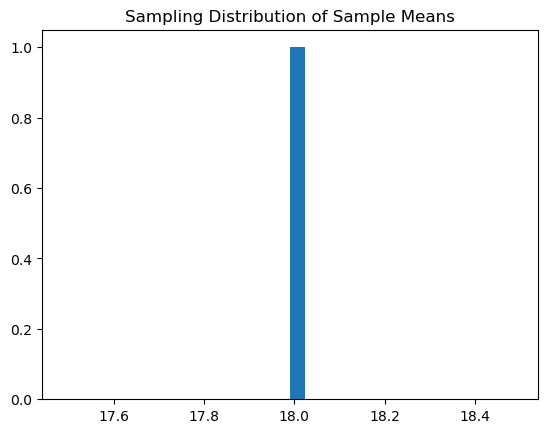

In [5]:
means.append(np.mean(sample))

import matplotlib.pyplot as plt

plt.hist(means, bins=30)
plt.title('Sampling Distribution of Sample Means')
plt.show()

 # Confidence Interval (CI) — Concept vs Point Estimation

- Range of values where population mean likely lies.
- "We are 95% confident..."

In [6]:
import scipy.stats as stats

sample_mean = np.mean(sample)
sample_std = np.std(sample, ddof=1)
n = len(sample)

conf_interval = stats.t.interval(
    0.95,
    df=n-1,
    loc=sample_mean,
    scale=sample_std/np.sqrt(n)
)

print(conf_interval)

(np.float64(15.57140592497164), np.float64(20.408594075028358))


# Margin of Error & Standard Error

- **Margin of Error = Critical Value × Standard Error**
- **Standard Error = σ / √n**

**Smaller samples → larger margin of error!**

# Z-Distribution vs T-Distribution

| Aspect | Z | T |
|---|---|---|
| **When** | Known σ | Unknown σ |
| **Sample Size** | Large | Small |
| **Example** | National census | Ola cab feedback from 30 users |

## Quiz 2

### Question:

You are analyzing Ola cab ratings from only **25 users**. Which distribution will you use?

a) Z-distribution  
b) T-distribution  

### Answer:

**b) T-distribution** ✅

**Reason:** The sample size is small (**n = 25**) and the population standard deviation (σ) is unknown.

# 🔄 Quick Recap

**Sampling → CLT → Confidence Interval → Z/T Distribution**

## 🔴 Step 1: Sampling

- We can't study the entire population, so we draw a **random sample**.
- Sampling should be **random and unbiased** to reflect the population properly.

### Example:

Take **200 random customers** from Paytm app users.

---

## 🔴 Step 2: Central Limit Theorem (CLT)

- If you repeatedly draw samples and calculate their **means**,
- The distribution of those sample means becomes **normal**,
- Even if the original population was **not normal** — when sample size is large (say, 30+).

### Importance:

CLT allows us to apply **normal curve logic (bell curve)** to samples.

---

## 🔴 Step 3: Confidence Interval

- Since sample mean ≠ population mean exactly,
- We create a **range (interval)** in which we are confident the true mean lies.

### Formula:

**Confidence Interval = Sample Mean ± (Critical Value × Standard Error)**

- Standard Error is related to sample size and sample standard deviation.
- **95% Confidence Interval → 95% sure true mean is inside this range.**

---

## 🔴 Step 4: Z-distribution / T-distribution

Depending on **sample size** and whether population standard deviation (**σ**) is known:

| Situation | Use |
|---|---|
| Large sample (n > 30), σ known | **Z-distribution** |
| Small sample (n < 30) or σ unknown | **T-distribution** |

### Examples:

- **Z-test:** When we know the standard deviation of SBI account balance.
- **T-test:** When we don't know the standard deviation and only have sample data.

# Why is 95% Confidence Interval = 1 − α?

## 🎯 What is α (Alpha)?

- **α (alpha)** is the **significance level**.
- It represents the total probability of error you are willing to accept.
- It is the chance that your confidence interval **does NOT contain the true population parameter**.

### Example:

If **α = 0.05**, it means there is a **5% risk** that the true mean is outside your confidence interval.

### Formula:

**Confidence Level = 1 − α**

For a 95% confidence level:

**1 − 0.05 = 0.95 = 95%**

## 🔖 Alpha (α)

- **Alpha (α) is the risk of being wrong.**
- **1 − Alpha is the confidence of being correct.**

### Simple Dialogue:

> "If you allow **5% room for mistake** (α = 0.05), you are **95% confident** that your interval has captured the true mean."

 - **Shade the middle 95% area** (confidence interval).
- The outer **5% (2.5% on each side)** is the **α (error zone)**.

## 🔥 Quick Summary Table

| Confidence Level | Alpha (α) |
|---|---:|
| 90% | 0.10 |
| 95% | 0.05 |
| 99% | 0.01 |

### 💡 Bonus Tip

> **Higher confidence (like 99%) means bigger intervals (wider range) because you are trying to be safer.**

## 🎯 Confidence Interval — Simple Example

Imagine you're trying to guess the **average height of all women in India**, but you can only measure **100 randomly selected women**.

- Sample size = **100 women**
- Sample average = **5'3"**

But the sample average might be a little different from the true population average.

So instead of saying:

> "The average is exactly 5'3"."

You say:

> **"I'm 95% confident the real average is between 5'2" and 5'4"."**

That's a **confidence interval**.

### 🧠 Core Message:

> **"It's a smart range where we believe the truth lies."** 

## 🛠️ Practical Analogy: Shooting Arrows 🎯

> Imagine shooting arrows at a hidden target. Each arrow is a **sample**, and the **bullseye is the true population mean**.

A confidence interval is like drawing a **circle around where your arrow landed** — saying:

> **"I'm 95% sure the bullseye is in this circle!"**

If you repeat this many times, **95 out of 100 intervals will capture the bullseye.**

---

## 💡 Understand the "95%" Part Carefully

**"95% confidence" doesn't mean there's a 95% chance the true value is in this one interval.**

Instead, it means:

> **If we repeated this experiment 100 times, about 95 of those intervals would include the true value.**

## 🔎 Real-Life Examples

### 1. 🏥 Healthcare

A sample of **1,000 patients** taking a new drug had an average blood pressure drop of **10 mmHg**.

**95% CI = [9.5 mmHg, 10.5 mmHg]**

### Interpretation:

> **"We are 95% confident that the true average effect of the drug lies between 9.5 and 10.5 mmHg."**

# ❗ Common Misunderstanding to Correct

🔴 **Don't say:**

> "There's a 95% chance the true mean is in this range."

🟢 **Do say:**

> "If we did this many times, 95% of the intervals we get would include the true mean."

---

> **"Confidence intervals don't tell us exactly where the truth is, but they give us a statistically sound range based on our data."**

### 🌉 Key Idea:

**Confidence intervals are a bridge between our _sample_ and the _real world_.**